# PhishGuard AI

## Deep Learning-Based Intelligent Phishing URL Detection System

**Domain:** Cybersecurity

**Algorithms:** CNN, BiLSTM, Hybrid CNN-BiLSTM

**Dataset:** 50,000 URLs

**Platform:** Website + Android + iOS

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn tensorflow joblib requests tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("===================================")
print(" PHISHGUARD AI - ENVIRONMENT READY")
print("===================================")

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Environment setup completed!")


 PHISHGUARD AI - ENVIRONMENT READY
TensorFlow: 2.21.0
NumPy: 2.3.5
Pandas: 2.3.3
Environment setup completed!


In [3]:

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("GPU detected!")
    print(gpus)
else:
    print("No GPU detected.")
    print("Training will use CPU.")


No GPU detected.
Training will use CPU.


In [4]:
import tensorflow as tf
import numpy as np
import pandas as pd

print("PhishGuard AI is ready!")
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("CPU:", tf.config.list_physical_devices('CPU'))

PhishGuard AI is ready!
TensorFlow: 2.21.0
NumPy: 2.3.5
Pandas: 2.3.3
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [5]:

import pandas as pd
import os

dataset_path = "../dataset/URL dataset.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


FileNotFoundError: [Errno 2] No such file or directory: '../dataset/URL dataset.csv'

In [6]:

import os

print("Current notebook directory:")
print(os.getcwd())

print("\nFiles and folders available:")
print(os.listdir())


Current notebook directory:
C:\Users\sathw\Documents\PhishGuard_AI

Files and folders available:
['.ipynb_checkpoints', 'app', 'dataset', 'models', 'notebooks', 'PhishGuard_AI_Training.ipynb', 'results']


In [7]:

dataset_folder = "../dataset"

print("Dataset folder exists:", os.path.exists(dataset_folder))

if os.path.exists(dataset_folder):
    print("\nFiles inside dataset folder:")
    print(os.listdir(dataset_folder))


Dataset folder exists: False


In [8]:
import os

print("Current notebook directory:")
print(os.getcwd())

print("\nFiles and folders available:")
print(os.listdir())

Current notebook directory:
C:\Users\sathw\Documents\PhishGuard_AI

Files and folders available:
['.ipynb_checkpoints', 'app', 'dataset', 'models', 'notebooks', 'PhishGuard_AI_Training.ipynb', 'results']


In [9]:
import os

dataset_path = "dataset"

print("Dataset folder exists:", os.path.exists(dataset_path))
print("Files inside dataset folder:", os.listdir(dataset_path))

Dataset folder exists: True
Files inside dataset folder: []


In [10]:
import pandas as pd

dataset_path = r"C:\Users\sathw\Downloads\URL dataset.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (450176, 2)


,url,type
0,https://www.google.com,legitimate
1,https://www.youtube.com,legitimate
2,https://www.facebook.com,legitimate
3,https://www.baidu.com,legitimate
4,https://www.wikipedia.org,legitimate


In [11]:
# Check dataset information

print("Dataset Information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["type"].value_counts())

print("\nDuplicate URLs:")
print(df["url"].duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450176 entries, 0 to 450175
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   url     450176 non-null  object
 1   type    450176 non-null  object
dtypes: object(2)
memory usage: 6.9+ MB
None

Missing values:
url     0
type    0
dtype: int64

Class distribution:
type
legitimate    345738
phishing      104438
Name: count, dtype: int64

Duplicate URLs:
0


In [12]:
import os
import shutil

source = r"C:\Users\sathw\Downloads\URL dataset.csv"
destination = r"C:\Users\sathw\Documents\PhishGuard_AI\dataset\URL dataset.csv"

shutil.copy2(source, destination)

print("Dataset copied successfully!")
print("File exists:", os.path.exists(destination))

Dataset copied successfully!
File exists: True


In [13]:
# Convert labels into numerical values

df["label"] = df["type"].map({
    "legitimate": 0,
    "phishing": 1
})

print("Label conversion completed!")
print(df[["url", "type", "label"]].head(10))

print("\nLabel distribution:")
print(df["label"].value_counts())

Label conversion completed!
                         url        type  label
0     https://www.google.com  legitimate      0
1    https://www.youtube.com  legitimate      0
2   https://www.facebook.com  legitimate      0
3      https://www.baidu.com  legitimate      0
4  https://www.wikipedia.org  legitimate      0
5     https://www.reddit.com  legitimate      0
6      https://www.yahoo.com  legitimate      0
7   https://www.google.co.in  legitimate      0
8         https://www.qq.com  legitimate      0
9     https://www.amazon.com  legitimate      0

Label distribution:
label
0    345738
1    104438
Name: count, dtype: int64


In [14]:
# URL preprocessing

df["url"] = df["url"].astype(str).str.lower().str.strip()

# Remove empty URLs
df = df[df["url"] != ""].copy()

# Reset index
df = df.reset_index(drop=True)

print("URL preprocessing completed!")
print("Total records:", len(df))

print("\nSample processed URLs:")
print(df[["url", "label"]].head(10))

print("\nMissing values:")
print(df[["url", "label"]].isnull().sum())

URL preprocessing completed!
Total records: 450176

Sample processed URLs:
                         url  label
0     https://www.google.com      0
1    https://www.youtube.com      0
2   https://www.facebook.com      0
3      https://www.baidu.com      0
4  https://www.wikipedia.org      0
5     https://www.reddit.com      0
6      https://www.yahoo.com      0
7   https://www.google.co.in      0
8         https://www.qq.com      0
9     https://www.amazon.com      0

Missing values:
url      0
label    0
dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

# Input and target
X = df["url"]
y = df["label"]

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Dataset splitting completed!")

print("\nTraining records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))
print("Total records:", len(X_train) + len(X_val) + len(X_test))

Dataset splitting completed!

Training records: 315123
Validation records: 67526
Testing records: 67527
Total records: 450176


In [16]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Maximum URL length
MAX_LEN = 200

# Create character-level tokenizer
tokenizer = Tokenizer(char_level=True, lower=True)

# Learn characters from training URLs only
tokenizer.fit_on_texts(X_train)

# Convert URLs into numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences to equal length
X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

print("Character tokenization completed!")
print("Vocabulary size:", len(tokenizer.word_index))
print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)

Character tokenization completed!
Vocabulary size: 140
Training shape: (315123, 200)
Validation shape: (67526, 200)
Testing shape: (67527, 200)


URL Length Statistics
Minimum length: 8
Maximum length: 2314
Average length: 60.24
Median length: 52.0

URLs longer than 200 characters: 4227
Percentage longer than 200 characters: 0.94 %


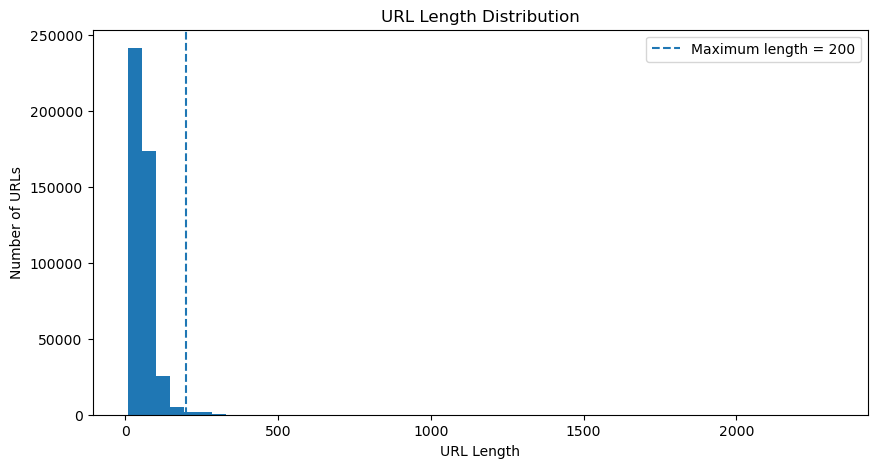

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate URL lengths
url_lengths = df["url"].str.len()

print("URL Length Statistics")
print("Minimum length:", url_lengths.min())
print("Maximum length:", url_lengths.max())
print("Average length:", round(url_lengths.mean(), 2))
print("Median length:", url_lengths.median())

print("\nURLs longer than 200 characters:",
      (url_lengths > MAX_LEN).sum())

print("Percentage longer than 200 characters:",
      round((url_lengths > MAX_LEN).mean() * 100, 2), "%")

# Plot URL length distribution
plt.figure(figsize=(10, 5))
plt.hist(url_lengths, bins=50)
plt.axvline(MAX_LEN, linestyle="--", label="Maximum length = 200")
plt.title("URL Length Distribution")
plt.xlabel("URL Length")
plt.ylabel("Number of URLs")
plt.legend()
plt.show()

In [18]:
import numpy as np

# Convert labels into NumPy arrays
y_train_np = np.array(y_train, dtype=np.int32)
y_val_np = np.array(y_val, dtype=np.int32)
y_test_np = np.array(y_test, dtype=np.int32)

# Verify input data
print("Final Model Input Preparation")
print("--------------------------------")

print("Training X:", X_train_pad.shape)
print("Training y:", y_train_np.shape)

print("Validation X:", X_val_pad.shape)
print("Validation y:", y_val_np.shape)

print("Testing X:", X_test_pad.shape)
print("Testing y:", y_test_np.shape)

print("\nData types:")
print("X:", X_train_pad.dtype)
print("y:", y_train_np.dtype)

print("\nNumber of classes:", len(np.unique(y_train_np)))

Final Model Input Preparation
--------------------------------
Training X: (315123, 200)
Training y: (315123,)
Validation X: (67526, 200)
Validation y: (67526,)
Testing X: (67527, 200)
Testing y: (67527,)

Data types:
X: int32
y: int32

Number of classes: 2


In [20]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout
)

# Build CNN model
cnn_model = Sequential([
    Input(shape=(MAX_LEN,), dtype="int32"),

    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=64
    ),

    Conv1D(
        filters=128,
        kernel_size=5,
        activation="relu"
    ),

    GlobalMaxPooling1D(),

    Dense(64, activation="relu"),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

# Compile CNN
cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 200, 64)             │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 196, 128)            │          41,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pooling1d_1               │ (None, 128)                 │               0 │
│ (GlobalMaxPooling1D)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 58,433 (228.25 KB)

 Trainable params: 58,433 (228.25 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Train CNN model

cnn_history = cnn_model.fit(
    X_train_pad,
    y_train_np,
    epochs=5,
    batch_size=256,
    validation_data=(X_val_pad, y_val_np),
    verbose=1
)

print("CNN training completed!")

Epoch 1/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 130s 103ms/step - accuracy: 0.9913 - loss: 0.0283 - val_accuracy: 0.9968 - val_loss: 0.0133
Epoch 2/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 142s 103ms/step - accuracy: 0.9971 - loss: 0.0136 - val_accuracy: 0.9972 - val_loss: 0.0098
Epoch 3/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 141s 102ms/step - accuracy: 0.9975 - loss: 0.0108 - val_accuracy: 0.9978 - val_loss: 0.0087
Epoch 4/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 127s 103ms/step - accuracy: 0.9979 - loss: 0.0090 - val_accuracy: 0.9976 - val_loss: 0.0087
Epoch 5/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 147s 120ms/step - accuracy: 0.9982 - loss: 0.0077 - val_accuracy: 0.9975 - val_loss: 0.0101
CNN training completed!


In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import numpy as np

# Predict probabilities
cnn_probabilities = cnn_model.predict(
    X_test_pad,
    batch_size=256
).ravel()

# Convert probabilities into classes
cnn_predictions = (cnn_probabilities >= 0.5).astype(int)

# Evaluation
print("CNN TEST RESULTS")
print("-------------------------")

print("Accuracy:",
      accuracy_score(y_test_np, cnn_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_np,
    cnn_predictions,
    target_names=["Legitimate", "Phishing"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_np, cnn_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test_np, cnn_probabilities))

264/264 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step
CNN TEST RESULTS
-------------------------
Accuracy: 0.9975121062686036

Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9970    0.9998    0.9984     51861
    Phishing     0.9992    0.9900    0.9946     15666

    accuracy                         0.9975     67527
   macro avg     0.9981    0.9949    0.9965     67527
weighted avg     0.9975    0.9975    0.9975     67527

Confusion Matrix:
[[51849    12]
 [  156 15510]]
ROC-AUC: 0.9997432692920057


In [24]:
import os
import json

# Create model directory
os.makedirs("../models", exist_ok=True)

# Save trained CNN model
cnn_model.save("../models/cnn_phishguard.keras")

# Save tokenizer configuration
with open("../models/tokenizer.json", "w") as f:
    f.write(tokenizer.to_json())

print("CNN model saved successfully!")
print("Tokenizer saved successfully!")

print("\nSaved files:")
print(os.listdir("../models"))

CNN model saved successfully!
Tokenizer saved successfully!

Saved files:
['cnn_phishguard.keras', 'tokenizer.json']


In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

# Build BiLSTM model
bilstm_model = Sequential([
    Input(shape=(MAX_LEN,), dtype="int32"),

    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=64
    ),

    Bidirectional(
        LSTM(64)
    ),

    Dropout(0.5),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

# Compile model
bilstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
bilstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ (None, 200, 64)             │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 128)                 │          66,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 83,393 (325.75 KB)

 Trainable params: 83,393 (325.75 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Train BiLSTM model

bilstm_history = bilstm_model.fit(
    X_train_pad,
    y_train_np,
    epochs=5,
    batch_size=256,
    validation_data=(X_val_pad, y_val_np),
    verbose=1
)

print("BiLSTM training completed!")

Epoch 1/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 959s 772ms/step - accuracy: 0.9916 - loss: 0.0340 - val_accuracy: 0.9967 - val_loss: 0.0184
Epoch 2/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 950s 772ms/step - accuracy: 0.9967 - loss: 0.0179 - val_accuracy: 0.9961 - val_loss: 0.0166
Epoch 3/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 949s 771ms/step - accuracy: 0.9966 - loss: 0.0171 - val_accuracy: 0.9969 - val_loss: 0.0149
Epoch 4/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 951s 772ms/step - accuracy: 0.9968 - loss: 0.0162 - val_accuracy: 0.9968 - val_loss: 0.0145
Epoch 5/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 969s 787ms/step - accuracy: 0.9969 - loss: 0.0154 - val_accuracy: 0.9971 - val_loss: 0.0137
BiLSTM training completed!


In [27]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict phishing probabilities
bilstm_probabilities = bilstm_model.predict(
    X_test_pad,
    batch_size=256
).ravel()

# Convert probabilities into classes
bilstm_predictions = (
    bilstm_probabilities >= 0.5
).astype(int)

# Evaluate model
print("BiLSTM TEST RESULTS")
print("-------------------------")

print("Accuracy:",
      accuracy_score(y_test_np, bilstm_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_np,
    bilstm_predictions,
    target_names=["Legitimate", "Phishing"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_np, bilstm_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test_np, bilstm_probabilities))

264/264 ━━━━━━━━━━━━━━━━━━━━ 57s 210ms/step
BiLSTM TEST RESULTS
-------------------------
Accuracy: 0.9970678395308543

Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9975    0.9987    0.9981     51861
    Phishing     0.9956    0.9917    0.9937     15666

    accuracy                         0.9971     67527
   macro avg     0.9966    0.9952    0.9959     67527
weighted avg     0.9971    0.9971    0.9971     67527

Confusion Matrix:
[[51793    68]
 [  130 15536]]
ROC-AUC: 0.9981274026563061


In [28]:
import os

os.makedirs("../models", exist_ok=True)

bilstm_model.save("../models/bilstm_phishguard.keras")

print("BiLSTM model saved successfully!")
print(os.listdir("../models"))

BiLSTM model saved successfully!
['bilstm_phishguard.keras', 'cnn_phishguard.keras', 'tokenizer.json']


In [29]:
import os

print("Project folder:")
print(os.getcwd())

print("\nModels folder:")
print(os.path.abspath("models"))

print("\nSaved files:")
print(os.listdir("models"))

Project folder:
C:\Users\sathw\Documents\PhishGuard_AI

Models folder:
C:\Users\sathw\Documents\PhishGuard_AI\models

Saved files:
[]


In [30]:
import os
import shutil

# Correct project models folder
correct_folder = os.path.abspath("models")
os.makedirs(correct_folder, exist_ok=True)

# Previous save location
old_folder = os.path.abspath("../models")

print("Old folder:", old_folder)
print("Files found:", os.listdir(old_folder))

# Copy model files into the correct folder
for filename in [
    "cnn_phishguard.keras",
    "bilstm_phishguard.keras",
    "tokenizer.json"
]:
    source = os.path.join(old_folder, filename)
    destination = os.path.join(correct_folder, filename)

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Copied:", filename)
    else:
        print("Not found:", filename)

print("\nCorrect models folder:")
print(os.listdir(correct_folder))

Old folder: C:\Users\sathw\Documents\models
Files found: ['bilstm_phishguard.keras', 'cnn_phishguard.keras', 'tokenizer.json']
Copied: cnn_phishguard.keras
Copied: bilstm_phishguard.keras
Copied: tokenizer.json

Correct models folder:
['bilstm_phishguard.keras', 'cnn_phishguard.keras', 'tokenizer.json']


In [31]:
url_symbols = [":", "/", ".", "?", "=", "-", "_", "@", "%"]

print("URL symbol verification:")
for symbol in url_symbols:
    print(repr(symbol), ":", tokenizer.word_index.get(symbol, "Not found"))

URL symbol verification:
':' : 20
'/' : 1
'.' : 8
'?' : 42
'=' : 39
'-' : 18
'_' : 30
'@' : 51
'%' : 45


In [32]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Conv1D,
    MaxPooling1D,
    Bidirectional,
    LSTM,
    Dropout,
    Dense
)

hybrid_model = Sequential([
    Input(shape=(MAX_LEN,), dtype="int32"),

    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=64
    ),

    # CNN feature extraction
    Conv1D(
        filters=128,
        kernel_size=5,
        activation="relu",
        padding="same"
    ),

    MaxPooling1D(pool_size=2),

    # BiLSTM sequence learning
    Bidirectional(LSTM(64)),

    Dropout(0.5),

    Dense(64, activation="relu"),

    Dropout(0.3),

    # Binary classification
    Dense(1, activation="sigmoid")
])

hybrid_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

hybrid_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)              │ (None, 200, 64)             │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 200, 128)            │          41,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 100, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ (None, 128)                 │          98,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 157,249 (614.25 KB)

 Trainable params: 157,249 (614.25 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
hybrid_history = hybrid_model.fit(
    X_train_pad,
    y_train_np,
    epochs=5,
    batch_size=256,
    validation_data=(X_val_pad, y_val_np),
    verbose=1
)

Epoch 1/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 629s 504ms/step - accuracy: 0.9921 - loss: 0.0283 - val_accuracy: 0.9968 - val_loss: 0.0148
Epoch 2/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 743s 602ms/step - accuracy: 0.9969 - loss: 0.0150 - val_accuracy: 0.9974 - val_loss: 0.0112
Epoch 3/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 640s 505ms/step - accuracy: 0.9973 - loss: 0.0117 - val_accuracy: 0.9973 - val_loss: 0.0104
Epoch 4/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 881s 667ms/step - accuracy: 0.9977 - loss: 0.0096 - val_accuracy: 0.9978 - val_loss: 0.0099
Epoch 5/5
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 700s 539ms/step - accuracy: 0.9981 - loss: 0.0083 - val_accuracy: 0.9981 - val_loss: 0.0086


In [34]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict test data
hybrid_probabilities = hybrid_model.predict(
    X_test_pad,
    batch_size=256
).ravel()

hybrid_predictions = (
    hybrid_probabilities >= 0.5
).astype(int)

# Evaluation
print("HYBRID CNN-BiLSTM TEST RESULTS")
print("--------------------------------")

print("Accuracy:",
      accuracy_score(y_test_np, hybrid_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_np,
    hybrid_predictions,
    target_names=["Legitimate", "Phishing"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_np, hybrid_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test_np, hybrid_probabilities))


264/264 ━━━━━━━━━━━━━━━━━━━━ 45s 166ms/step
HYBRID CNN-BiLSTM TEST RESULTS
--------------------------------
Accuracy: 0.997956373006353

Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9978    0.9996    0.9987     51861
    Phishing     0.9985    0.9927    0.9956     15666

    accuracy                         0.9980     67527
   macro avg     0.9982    0.9961    0.9971     67527
weighted avg     0.9980    0.9980    0.9980     67527

Confusion Matrix:
[[51838    23]
 [  115 15551]]
ROC-AUC: 0.9996097442639816


In [35]:
import os

models_folder = os.path.abspath("models")
os.makedirs(models_folder, exist_ok=True)

hybrid_model.save(
    os.path.join(models_folder, "hybrid_phishguard.keras")
)

print("Hybrid model saved successfully!")

print("\nAll saved models:")
print(os.listdir(models_folder))

Hybrid model saved successfully!

All saved models:
['bilstm_phishguard.keras', 'cnn_phishguard.keras', 'hybrid_phishguard.keras', 'tokenizer.json']


In [36]:
%pip install flask

Note: you may need to restart the kernel to use updated packages.


In [37]:
import os
import json
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.text import tokenizer_from_json

# Project model directory
models_folder = os.path.abspath("models")

# Load Hybrid CNN-BiLSTM
hybrid_model_loaded = load_model(
    os.path.join(models_folder, "hybrid_phishguard.keras")
)

# Load character tokenizer
with open(
    os.path.join(models_folder, "tokenizer.json"),
    "r",
    encoding="utf-8"
) as file:
    tokenizer_json = file.read()

loaded_tokenizer = tokenizer_from_json(tokenizer_json)

print("Hybrid model loaded successfully!")
print("Tokenizer loaded successfully!")
print("Maximum URL length:", MAX_LEN)
print("Vocabulary size:", len(loaded_tokenizer.word_index))

Hybrid model loaded successfully!
Tokenizer loaded successfully!
Maximum URL length: 200
Vocabulary size: 140


In [38]:

%%writefile app/app.py

import os
import json
import numpy as np

from flask import Flask, request, jsonify, render_template
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Flask configuration
app = Flask(__name__)

# Project paths
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODELS_DIR = os.path.join(BASE_DIR, "..", "models")

MAX_LEN = 200

# Load trained Hybrid model
model = load_model(
    os.path.join(MODELS_DIR, "hybrid_phishguard.keras")
)

# Load character tokenizer
with open(
    os.path.join(MODELS_DIR, "tokenizer.json"),
    "r",
    encoding="utf-8"
) as file:
    tokenizer = tokenizer_from_json(file.read())


@app.route("/")
def home():
    return render_template("index.html")


@app.route("/predict", methods=["POST"])
def predict():

    try:
        data = request.get_json(silent=True) or {}
        url = data.get("url", "")

        if not isinstance(url, str) or not url.strip():
            return jsonify({
                "error": "Please enter a valid URL."
            }), 400

        url = url.lower().strip()

        # Convert URL into character sequences
        sequence = tokenizer.texts_to_sequences([url])

        padded = pad_sequences(
            sequence,
            maxlen=MAX_LEN,
            padding="post",
            truncating="post"
        )

        # Predict phishing probability
        probability = float(
            model.predict(padded, verbose=0)[0][0]
        )

        prediction = (
            "Phishing" if probability >= 0.5
            else "Legitimate"
        )

        confidence = (
            probability if prediction == "Phishing"
            else 1 - probability
        ) * 100

        return jsonify({
            "url": url,
            "prediction": prediction,
            "confidence": round(confidence, 2),
            "phishing_probability": round(probability * 100, 2)
        })

    except Exception as error:
        return jsonify({
            "error": str(error)
        }), 500


if __name__ == "__main__":
    app.run(debug=True, host="127.0.0.1", port=5000)


Writing app/app.py


In [39]:
from pathlib import Path

template_path = Path("app/templates/index.html")
template_path.parent.mkdir(parents=True, exist_ok=True)

html_code = """PASTE_HTML_CODE_HERE"""

template_path.write_text(html_code, encoding="utf-8")

print("HTML file created successfully!")
print("File location:", template_path.resolve())

HTML file created successfully!
File location: C:\Users\sathw\Documents\PhishGuard_AI\app\templates\index.html


In [40]:

from pathlib import Path

html_code = r"""
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>PhishGuard AI | URL Security</title>
<style>
*{box-sizing:border-box}
body{margin:0;font-family:Arial,sans-serif;background:#08111f;color:#eaf2ff}
header{padding:22px 7%;display:flex;justify-content:space-between;
align-items:center;border-bottom:1px solid #20334c}
.logo{font-size:25px;font-weight:bold;color:#42d9bd}
.logo span{color:white}
.status{color:#42d9bd;font-size:13px}
main{max-width:1050px;margin:55px auto;padding:20px}
.hero{text-align:center;margin-bottom:35px}
.hero h1{font-size:38px;margin-bottom:12px}
.hero h1 span{color:#42d9bd}
.hero p{color:#9fb1c8;line-height:1.6}
.panel{background:#111e30;border:1px solid #263b55;border-radius:18px;
padding:28px;margin-bottom:22px}
label{display:block;margin-bottom:12px;font-weight:bold}
input,select{width:100%;padding:16px;border-radius:9px;
border:1px solid #38516e;background:#091525;color:white;font-size:15px}
button{width:100%;padding:16px;margin-top:16px;border:0;
border-radius:9px;background:#22c9ae;color:#06141c;
font-weight:bold;font-size:16px;cursor:pointer}
button:hover{background:#49e4c9}
button:disabled{opacity:.6;cursor:wait}
.result{display:none;margin-top:20px;padding:22px;border-radius:12px;
background:#091525;border:1px solid #38516e}
.result h2{margin-top:0}
.safe{color:#42d9bd}.danger{color:#ff6577}
.muted{color:#9fb1c8}
footer{text-align:center;color:#71849d;padding:25px;font-size:13px}
@media(max-width:600px){.hero h1{font-size:29px}main{margin:25px auto}}
</style>
</head>
<body>
<header>
 <div class="logo">🛡 PhishGuard <span>AI</span></div>
 <div class="status">● AI SECURITY SYSTEM</div>
</header>

<main>
 <section class="hero">
  <h1>Intelligent <span>Phishing URL</span> Detection</h1>
  <p>Protect yourself from malicious websites using Deep Learning.<br>
  Analyze suspicious URLs with our trained AI model.</p>
 </section>

 <section class="panel">
  <label for="url">Enter website URL</label>
  <input id="url" type="text" placeholder="https://example.com">
  <label for="model" style="margin-top:20px">Select Deep Learning Model</label>
  <select id="model">
   <option value="hybrid">Hybrid CNN-BiLSTM</option>
   <option value="cnn">CNN</option>
   <option value="bilstm">BiLSTM</option>
  </select>
  <button id="scan" onclick="scanURL()">🔍 Scan Website</button>
  <div class="result" id="result">
   <h2 id="prediction"></h2>
   <p id="confidence"></p>
   <p class="muted" id="details"></p>
  </div>
 </section>

 <section class="panel">
  <h2>About PhishGuard AI</h2>
  <p class="muted">PhishGuard AI uses character-level deep learning
  architectures to identify suspicious URL patterns and classify
  URLs as legitimate or phishing.</p>
  <p class="muted">Models: CNN | BiLSTM | Hybrid CNN-BiLSTM</p>
 </section>
</main>

<footer>PhishGuard AI | Deep Learning Cybersecurity Project</footer>

<script>
async function scanURL(){
 const url=document.getElementById("url").value.trim();
 const model=document.getElementById("model").value;
 const button=document.getElementById("scan");
 const result=document.getElementById("result");

 if(!url){alert("Please enter a URL.");return;}

 button.disabled=true;
 button.textContent="Analyzing URL...";
 result.style.display="none";

 try{
  const response=await fetch("/predict",{
   method:"POST",
   headers:{"Content-Type":"application/json"},
   body:JSON.stringify({url:url,model:model})
  });
  const data=await response.json();
  if(!response.ok) throw new Error(data.error||"Prediction failed");

  const phishing=String(data.prediction).toLowerCase().includes("phish");
  document.getElementById("prediction").textContent=
   phishing?"⚠ PHISHING URL DETECTED":"✓ LEGITIMATE URL";
  document.getElementById("prediction").className=
   phishing?"danger":"safe";
  document.getElementById("confidence").textContent=
   "Confidence: "+Number(data.confidence).toFixed(2)+"%";
  document.getElementById("details").textContent=
   "Model: "+(data.model||model.toUpperCase());
  result.style.display="block";
 }catch(error){
  result.style.display="block";
  document.getElementById("prediction").textContent="Unable to scan URL";
  document.getElementById("prediction").className="danger";
  document.getElementById("confidence").textContent=error.message;
  document.getElementById("details").textContent=
   "Check that the Flask backend is running.";
 }finally{
  button.disabled=false;
  button.textContent="🔍 Scan Website";
 }
}
</script>
</body>
</html>
"""

path = Path("app/templates/index.html")
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(html_code, encoding="utf-8")

print("PhishGuard AI dashboard HTML saved!")
print("File:", path.resolve())
print("Size:", path.stat().st_size, "bytes")


PhishGuard AI dashboard HTML saved!
File: C:\Users\sathw\Documents\PhishGuard_AI\app\templates\index.html
Size: 4706 bytes


In [41]:

from pathlib import Path

app_code = r'''
from flask import Flask, render_template, request, jsonify
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import tokenizer_from_json
import json
import os

app = Flask(__name__)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_DIR = os.path.join(BASE_DIR, "..", "models")

# Load tokenizer
with open(os.path.join(MODEL_DIR, "tokenizer.json"), "r") as f:
    tokenizer = tokenizer_from_json(f.read())

MAX_LEN = 200

# Load trained models
models = {
    "cnn": load_model(os.path.join(MODEL_DIR, "cnn_phishguard.keras")),
    "bilstm": load_model(os.path.join(MODEL_DIR, "bilstm_phishguard.keras")),
    "hybrid": load_model(os.path.join(MODEL_DIR, "hybrid_phishguard.keras"))
}

print("All PhishGuard AI models loaded successfully!")

@app.route("/")
def home():
    return render_template("index.html")

@app.route("/predict", methods=["POST"])
def predict():
    try:
        data = request.get_json(silent=True) or {}

        url = str(data.get("url", "")).strip().lower()
        model_name = str(data.get("model", "hybrid")).lower()

        if not url:
            return jsonify({"error": "Please enter a URL"}), 400

        if model_name not in models:
            return jsonify({"error": "Invalid model selected"}), 400

        # Convert URL into character sequence
        sequence = tokenizer.texts_to_sequences([url])
        padded = pad_sequences(
            sequence,
            maxlen=MAX_LEN,
            padding="post",
            truncating="post"
        )

        # Predict
        probability = float(
            models[model_name].predict(padded, verbose=0)[0][0]
        )

        if probability >= 0.5:
            prediction = "Phishing"
            confidence = probability * 100
        else:
            prediction = "Legitimate"
            confidence = (1 - probability) * 100

        return jsonify({
            "prediction": prediction,
            "confidence": round(confidence, 2),
            "model": model_name.upper()
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500

if __name__ == "__main__":
    app.run(debug=True)
'''

app_path = Path("app/app.py")
app_path.parent.mkdir(parents=True, exist_ok=True)
app_path.write_text(app_code, encoding="utf-8")

print("Flask backend created successfully!")
print("Location:", app_path.resolve())


Flask backend created successfully!
Location: C:\Users\sathw\Documents\PhishGuard_AI\app\app.py


In [42]:
from pathlib import Path

template = Path(
    r"C:\Users\sathw\Documents\PhishGuard_AI\app\templates"
)

# Check existing files
print("Existing files:")
for file in template.iterdir():
    print(file.name)

# Create or overwrite the correct HTML file
html_file = template / "index.html"

if not html_file.exists():
    html_file.write_text(
        "<h1>PhishGuard AI</h1>",
        encoding="utf-8"
    )

print("\nCorrect HTML file:", html_file.exists())
print("File size:", html_file.stat().st_size, "bytes")

Existing files:
.ipynb_checkpoints
index.html

Correct HTML file: True
File size: 4706 bytes


In [43]:
import os
import shutil

project_path = r"C:\Users\sathw\Documents\PhishGuard_AI"
zip_path = r"C:\Users\sathw\Documents\PhishGuard_AI_Project"

# Check important project files
required_files = [
    "app/app.py",
    "app/templates/index.html",
    "models/cnn_phishguard.keras",
    "models/bilstm_phishguard.keras",
    "models/hybrid_phishguard.keras",
    "models/tokenizer.json"
]

print("Checking project files:")

for file in required_files:
    full_path = os.path.join(project_path, file)
    print(("FOUND: " if os.path.exists(full_path) else "MISSING: ") + file)

# Create ZIP archive
shutil.make_archive(zip_path, "zip", project_path)

print("\nZIP created successfully!")
print(zip_path + ".zip")

Checking project files:
FOUND: app/app.py
FOUND: app/templates/index.html
FOUND: models/cnn_phishguard.keras
FOUND: models/bilstm_phishguard.keras
FOUND: models/hybrid_phishguard.keras
FOUND: models/tokenizer.json

ZIP created successfully!
C:\Users\sathw\Documents\PhishGuard_AI_Project.zip
